# DummyClassifier — v1

**Lê Văn Hiếu — 3124411091 · Nhóm 10 · UCI 697**

Thiết lập mốc luôn đoán lớp phổ biến nhất để đánh giá các mô hình học từ đặc trưng.

Notebook này chỉ trình bày/chạy **DummyClassifier v1**. Code và cấu hình ở `models/m01_baseline/v1/`; notebook từng phiên bản ở `notebooks/m01_baseline/v1.ipynb`, sau này thêm v2–v10 khi có thí nghiệm tương ứng.

Mặc định **Run All đọc run đã huấn luyện**, không fit lại. Mục 5 cho phép chạy mới bằng code dùng chung, tạo `run_id` mới và không ghi đè kết quả. Chạy lại cùng cấu hình vẫn là v1, không tự tăng version.

Chọn kernel `.venv`. Từ gốc repo: `python -m pip install -r final/requirements-notebook.txt`.

## 1. Môi trường và đường dẫn

Tự tìm final/ từ vị trí notebook; không dùng đường dẫn riêng của tác giả.

In [1]:
from pathlib import Path
import sys
import os
import json
import hashlib
import importlib.util
import platform
import pandas as pd
import numpy as np
import yaml
from IPython.display import display, Image

candidates = [p for base in [Path.cwd(), *Path.cwd().parents] for p in [base, base / 'final']]
FINAL = next(p.resolve() for p in candidates if (p / 'src/data.py').is_file() and (p / 'data/raw/data.csv').is_file())
sys.path.insert(0, str(FINAL))
os.environ.setdefault('MPLCONFIGDIR', str(FINAL.parent / '.venv/matplotlib-cache'))
from src.data import load_student_data, load_splits, LABELS
from src.features import make_preprocessor
from src.evaluate import run_cv_experiment

print('Python:', platform.python_version())
print('Project:', FINAL.name)

Python: 3.12.14
Project: final


## 2. Dữ liệu và nhãn

Loader kiểm chứng checksum/schema, giữ nguyên thứ tự dòng và tách Target riêng ở y; không sửa CSV nguồn.

In [2]:
X, y = load_student_data()
assert X.shape == (4424, 36) and 'Target' not in X.columns
source = json.loads((FINAL / 'data/source_manifest.json').read_text(encoding='utf-8'))
print('X:', X.shape, '| y:', y.shape)
print('SHA-256:', source['csv_sha256'])
display(y.value_counts().reindex(LABELS).rename_axis('Nhãn').to_frame('Số mẫu'))

X: (4424, 36) | y: (4424,)
SHA-256: 3ef126de5cefff26eb11fbb4237f1a1401cb64b488e2f1d598c23cedeb4c45ae


,Số mẫu
Nhãn,
Dropout,1421
Enrolled,794
Graduate,2209


## 3. Bộ chia chung và tiền xử lý

80/20 stratify, seed 42; CV 5-fold trên Train. Nạp file chỉ số có sẵn, không chia riêng. Vị trí trong folds tương đối với X_train.

Dummy không cần encoding/scaling vì không học quan hệ giữa đặc trưng và nhãn. Ở mỗi fold, lớp phổ biến chỉ được xác định từ phần Train của fold.

In [3]:
train_ids, test_ids, folds, split_manifest = load_splits()
X_train, y_train = X.iloc[train_ids], y.iloc[train_ids]
assert not set(train_ids) & set(test_ids)
print('Train:', len(train_ids), '| Test:', len(test_ids), '| CV:', len(folds))
fold_summary = []
for number, (fit, valid) in enumerate(folds, 1):
    row = {'Fold': number, 'Fit': len(fit), 'Validation': len(valid)}
    row.update({label: int((y_train.iloc[valid] == label).sum()) for label in LABELS})
    fold_summary.append(row)
display(pd.DataFrame(fold_summary).set_index('Fold'))

print('Dummy không dùng preprocessing.')

Train: 3539 | Test: 885 | CV: 5


,Fit,Validation,Dropout,Enrolled,Graduate
Fold,,,,,
1,2831,708,227,127,354
2,2831,708,227,127,354
3,2831,708,228,127,353
4,2831,708,228,127,353
5,2832,707,227,127,353


Dummy không dùng preprocessing.


## 4. Cấu hình và model factory

strategy=most_frequent, random_state=42; không tuning. Không cần tạo nhiều phiên bản Dummy chỉ để đủ số lượng.

In [4]:
MODEL_ID = 'm01_baseline'
model_dir = FINAL / 'models' / MODEL_ID / 'v1'
spec = importlib.util.spec_from_file_location(f'train_{MODEL_ID}_v1', model_dir / 'train.py')
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)
config = yaml.safe_load((model_dir / 'config.yaml').read_text(encoding='utf-8'))
assert config['model_id'] == MODEL_ID and config['version'] == 'v1'
print('Tham số:', config['params'])
print(module.make_model(config))

Tham số: {'strategy': 'most_frequent', 'random_state': 42}
DummyClassifier(random_state=42, strategy='most_frequent')


## 5. Đọc run đã có hoặc huấn luyện mới

`RUN_NEW_EXPERIMENT = False`: chỉ đọc kết quả DummyClassifier v1 đã huấn luyện. Đổi thành True để fit 5 fold và fit lại toàn Train; tạo run mới cho riêng model này. Không tạo run của mô hình khác. Không dự đoán hoặc đánh giá Test.

Không chạy nhiều notebook cùng ghi experiments/results.csv đồng thời trong một checkout.

In [5]:
RUN_NEW_EXPERIMENT = False
if RUN_NEW_EXPERIMENT:
    run_path = run_cv_experiment(model_dir / 'config.yaml', module.make_model)
else:
    run_path = FINAL / 'experiments/runs/m01_baseline_v1_20261104T070423_6b66b3d6'
    print('Đọc run đã huấn luyện; không fit lại trong lần Run All này.')
assert run_path.is_dir(), 'Chưa có thư mục run'
print('Run:', run_path.name)

Đọc run đã huấn luyện; không fit lại trong lần Run All này.
Run: m01_baseline_v1_20261104T070423_6b66b3d6


## 6. Kết quả CV và độ ổn định

Trung bình 5 fold, std ddof=0. Theo dõi Macro-F1, Accuracy, Recall Dropout và gap Train–Validation; không gọi các số này là Test.

,Macro-F1 CV,Std (ddof=0),Accuracy CV,Recall Dropout CV,Train Macro-F1,Gap Train–Validation
Model,,,,,,
m01_baseline,0.222,0.0002,0.4993,0.0,0.222,0.0


,fold,train_f1_macro,valid_f1_macro,valid_accuracy,valid_recall_Dropout,gap_f1_macro
0,1,0.2220,0.2222,0.5000,0.0,-0.0003
1,2,0.2220,0.2222,0.5000,0.0,-0.0003
2,3,0.2221,0.2218,0.4986,0.0,0.0003
3,4,0.2221,0.2218,0.4986,0.0,0.0003
4,5,0.2220,0.2220,0.4993,0.0,0.0000


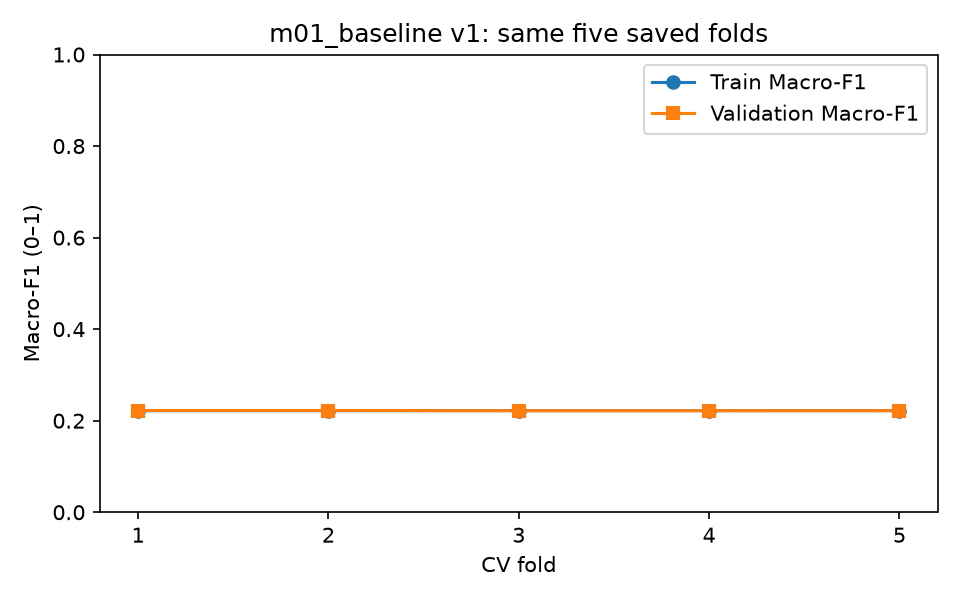

In [6]:
recorded_config = yaml.safe_load((run_path / 'config.yaml').read_text(encoding='utf-8'))
assert recorded_config == config, 'Config khác run; cần chọn đúng version hoặc chạy mới.'
tracking = json.loads((run_path / 'tracking.json').read_text(encoding='utf-8'))
assert tracking['status'] == 'complete'
metrics = json.loads((run_path / 'metrics.json').read_text(encoding='utf-8'))
assert metrics['model_id'] == MODEL_ID and not metrics['test_scored_this_run']
cv = metrics['cv']
display(pd.DataFrame([{
    'Model': MODEL_ID, 'Macro-F1 CV': cv['valid_f1_macro_mean'],
    'Std (ddof=0)': cv['valid_f1_macro_std'], 'Accuracy CV': cv['valid_accuracy_mean'],
    'Recall Dropout CV': cv['valid_recall_Dropout_mean'],
    'Train Macro-F1': cv['train_f1_macro_mean'], 'Gap Train–Validation': cv['gap_f1_macro_mean'],
}]).set_index('Model').round(4))
display(pd.read_csv(run_path / 'fold_metrics.csv')[
    ['fold', 'train_f1_macro', 'valid_f1_macro', 'valid_accuracy', 'valid_recall_Dropout', 'gap_f1_macro']].round(4))
display(Image(filename=str(run_path / 'figures/cv_macro_f1.png')))

Dummy luôn dự đoán Graduate: Accuracy CV khoảng 49,93% nhưng Recall Dropout và Enrolled đều bằng 0; Macro-F1 CV chỉ khoảng 0,2220. Mốc này cho thấy không thể đánh giá bài toán chỉ bằng Accuracy. Gap gần 0 không có nghĩa Dummy là mô hình hữu ích.

## 7. OOF, lỗi từng lớp và confusion matrix

Mỗi sinh viên Train có một dự đoán từ model không học mẫu đó trong fold. OOF gộp khác CV mean; ma trận có hàng là nhãn thật và cột là dự đoán.

,precision,recall,f1-score,support
label,,,,
Dropout,0.0000,0.0,0.000,1137.0
Enrolled,0.0000,0.0,0.000,635.0
Graduate,0.4993,1.0,0.666,1767.0


Macro-F1 OOF: 0.222


,Dropout,Enrolled,Graduate
true_label,,,
Dropout,0,0,1137
Enrolled,0,0,635
Graduate,0,0,1767


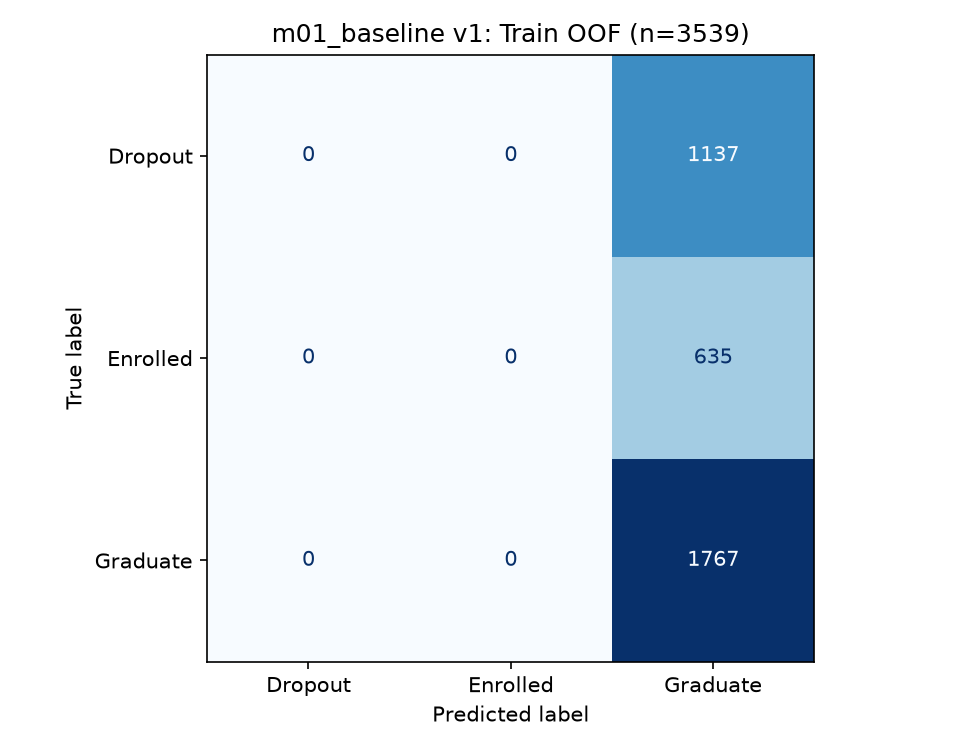

Dropout bị bỏ sót: 1137
Cảnh báo Dropout nhầm: 0


In [7]:
classes = pd.read_csv(run_path / 'class_metrics_oof.csv')
display(classes.set_index('label').round(4))
print('Macro-F1 OOF:', round(metrics['oof']['f1_macro'], 4))
cm = pd.read_csv(run_path / 'confusion_matrix.csv', index_col=0)
display(cm)
display(Image(filename=str(run_path / 'figures/confusion_matrix.png')))
print('Dropout bị bỏ sót:', int(cm.loc['Dropout'].sum() - cm.loc['Dropout', 'Dropout']))
print('Cảnh báo Dropout nhầm:', int(cm['Dropout'].sum() - cm.loc['Dropout', 'Dropout']))

Ma trận cho thấy toàn bộ 1.137 Dropout và 635 Enrolled trong Train OOF bị đoán Graduate. Dummy không phát hiện được sinh viên bỏ học. Đây là kết quả kỳ vọng của chiến lược most_frequent, dùng làm mốc để LR/DT/RF/XGBoost chứng minh giá trị.

## 8. Truy vết, giới hạn và phiên bản tiếp theo

Run này đã được đối chiếu với kết quả giữa kỳ: metrics khớp trong sai số 1e-12 và OOF trùng hoàn toàn. Git/source hashes ghi code thực dùng; verification.json ghi kiểm chứng độc lập. Run mới chỉ có kiểm tra runtime cho đến khi được đối chiếu riêng.

W&B/Sheets chưa đồng bộ vì checkout chưa có cấu hình. Model joblib chỉ lưu cục bộ; chạy mới để tạo lại. Không nạp model từ nguồn không tin cậy.

Run này không đánh giá Test. Test từng được RF cũ sử dụng; đổi cấu trúc không xóa lịch sử đó. Dữ liệu có HK2 nên không gọi đây là dự đoán ngay khi nhập học.

Giữ Dummy v1 làm mốc cố định; ưu tiên cải tiến các mô hình học từ dữ liệu. Chỉ tạo v2 nếu có thay đổi baseline có mục đích, không tạo đủ 10 bản theo hình thức.

In [8]:
info = json.loads((run_path / 'git_info.json').read_text(encoding='utf-8'))
changed = [name for name, digest in info['source_sha256'].items()
           if hashlib.sha256((FINAL / name).read_bytes()).hexdigest() != digest]
print('Source hiện tại khớp lúc chạy:', not changed)
if changed:
    print('File đã thay đổi:', changed)
verify_path = run_path / 'verification.json'
if verify_path.exists():
    print('Kiểm chứng độc lập:', len(json.loads(verify_path.read_text(encoding='utf-8'))['checks_passed']), 'mục đạt')
else:
    print('Run mới chưa có biên bản kiểm chứng độc lập.')
print('Bằng chứng:', run_path.relative_to(FINAL).as_posix())
print('W&B:', tracking['wandb_status'])

Source hiện tại khớp lúc chạy: True
Kiểm chứng độc lập: 12 mục đạt
Bằng chứng: experiments/runs/m01_baseline_v1_20261104T070423_6b66b3d6
W&B: not_configured
